In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time


from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, StandardScaler, RobustScaler
from sklearn.impute import KNNImputer
from sklearn import metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


import folium
from folium.plugins import MarkerCluster
from folium import plugins
from folium.plugins import FastMarkerCluster
from folium.plugins import HeatMap


warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter("ignore", category=ConvergenceWarning)

In [2]:
df = pd.read_csv("AB_NYC_2019.csv")

df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.isnull().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

In [6]:
Label_Encoder = LabelEncoder()
df["room_type"] = Label_Encoder.fit_transform(df["room_type"])
df["neighbourhood"] = Label_Encoder.fit_transform(df["neighbourhood"])
df["neighbourhood_group"] = Label_Encoder.fit_transform(df["neighbourhood_group"])

In [7]:
drop_list = ["name","id","host_id","host_name","last_review"]

df = df.drop(drop_list, axis=1)

In [8]:
df.head()

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,1,108,40.64749,-73.97237,1,149,1,9,0.21,6,365
1,2,127,40.75362,-73.98377,0,225,1,45,0.38,2,355
2,2,94,40.80902,-73.94190,1,150,3,0,NaN,1,365
3,1,41,40.68514,-73.95976,0,89,1,270,4.64,1,194
4,2,61,40.79851,-73.94399,0,80,10,9,0.10,1,0


In [11]:
long = 73.80
lat = 40.80

locations = list(zip(df.latitude,df.longitude))

map1 = folium.Map(locations=[lat,long], zoom_start=9)
FastMarkerCluster(data=locations).add_to(map1)
print("Visualizing Geographic Locations on an Interactive Map")
map1

Visualizing Geographic Locations on an Interactive Map


In [ ]:
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)
df["reviews_per_month"].head()

0    0.210000
1    0.380000
2    1.373221
3    4.640000
4    0.100000
Name: reviews_per_month, dtype: float64

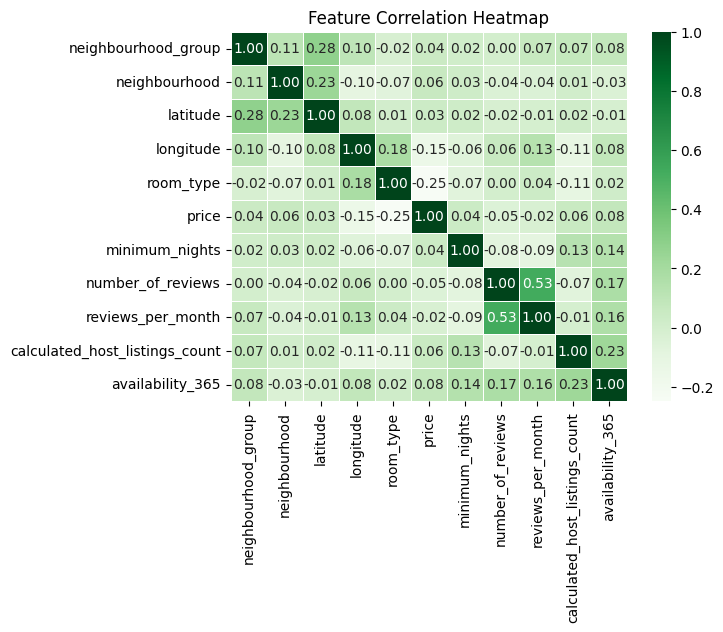

In [ ]:
# العلاقة بين الاعمدة
plt.Figure(figsize=(6,4))
sns.heatmap(df.corr(),annot=True, cmap="Greens", fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

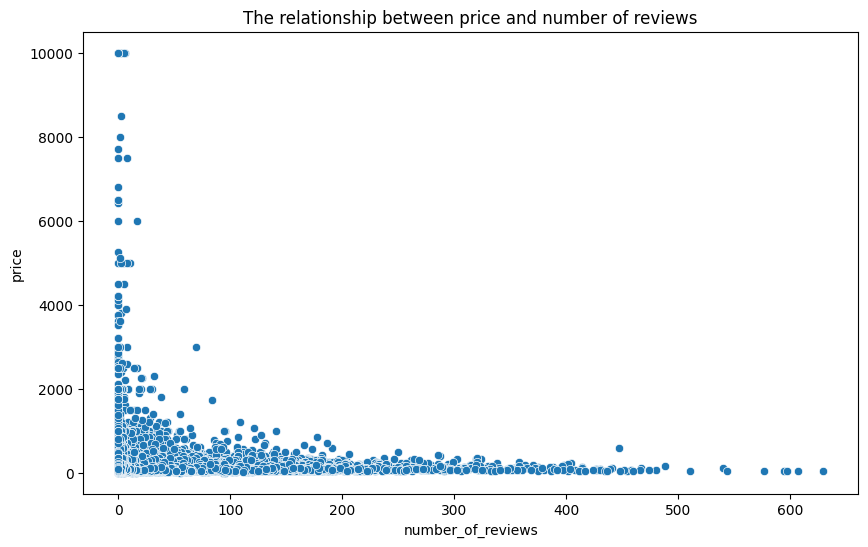

In [102]:
# العلاقة بين السعر وعدد المراجعات
plt.figure(figsize=(10, 6))
sns.scatterplot(x='number_of_reviews', y='price', data=df)
plt.title("The relationship between price and number of reviews")
plt.xlabel("number_of_reviews")
plt.ylabel('price')
plt.show()

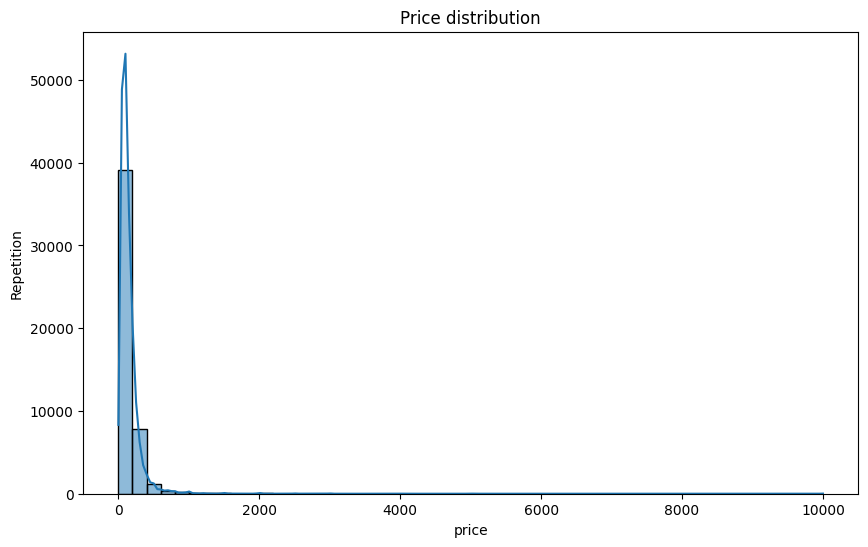

In [103]:
# توزيع السعر
plt.figure(figsize=(10, 6))
sns.histplot(df['price'], bins=50, kde=True)
plt.title('Price distribution')
plt.xlabel('price')
plt.ylabel('Repetition')
plt.show()

In [53]:
X = df.drop(["price"], axis=1)
y = df["price"]

In [68]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [81]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)


Intercept: -52485.99097925183
Coefficients: [ 1.11310022e+01  9.85966089e-02  1.37411301e+02 -6.36189100e+02
 -1.01025839e+02  4.86852746e-02 -3.84365862e-01  3.22237743e+00
 -9.72920250e-02  1.98150988e-01]


In [73]:
y_pred = model.predict(X_test)

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"R² Score: {r2}") # Should be close to 1 for a good model

Mean Absolute Error (MAE): 72.90625920712021
Mean Squared Error (MSE): 35505.46687239929
R² Score: 0.12087561956554582


In [85]:
model2 = LogisticRegression()
model2.fit(X_train,y_train)

print("Intercept:", model2.intercept_)
print("Coefficients:", model2.coef_)

Intercept: [ 1.43625989e-04 -5.86664367e-05 -2.45380792e-04  2.45267312e-05
 -1.53587886e-04 -1.21708514e-05 -1.14737820e-04 -1.56118393e-04
  1.84835292e-04 -7.78445500e-05  1.88944790e-04  2.37947696e-05
  1.15431092e-04  4.28840756e-04  1.07681242e-04  2.92139306e-04
  3.57589666e-04  3.95543793e-04  5.93882196e-04  4.40499828e-04
  4.20243876e-04  3.50417917e-04  3.30464111e-04  6.70868051e-04
  4.49325909e-04  4.61180630e-04  5.05268961e-04  5.49367073e-04
  7.42087167e-04  4.05787103e-04  5.45294877e-04  4.12273763e-04
  4.69967230e-04  7.78692734e-04  4.59490803e-04  4.43309245e-04
  5.42075267e-04  5.55493254e-04  8.36331349e-04  4.06409835e-04
  3.99253375e-04  3.64394558e-04  3.92798506e-04  7.46601935e-04
  3.63545715e-04  4.21897392e-04  3.87329557e-04  5.26515544e-04
  7.96062233e-04  2.94792036e-04  4.22498757e-04  4.03525108e-04
  3.48844648e-04  7.41345015e-04  3.89284210e-04  3.45317958e-04
  4.55165783e-04  5.44774913e-04  7.63190085e-04  3.13564623e-04
  3.73432355e-

In [ ]:
y_pred = model2.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"R² Score: {r2}") # Should be close to 1 for a good model

Mean Absolute Error (MAE): 80.29892971572704
Mean Squared Error (MSE): 40738.45504124344
R² Score: -0.00869449701084446


In [95]:
knn = KNeighborsRegressor(n_neighbors=15)
knn.fit(X_train,y_train)

KNeighborsRegressor(n_neighbors=15)

In [96]:
# Predict on test data
y_pred = knn.predict(X_test)

# Compare actual vs predicted prices
results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print(results)


       Actual   Predicted
879        89  129.533333
44383      30  115.600000
15394     120  127.200000
43230     470  344.200000
16332     199  116.400000
...       ...         ...
9370       65  181.333333
34442      55  129.600000
9164       90  201.800000
11841      95  107.000000
46958      97  235.400000

[14669 rows x 2 columns]


In [97]:
# Calculate errors
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"R² Score: {r2}")  # Should be close to 1 for a good model


Mean Absolute Error (MAE): 82.76155157134092
Mean Squared Error (MSE): 38757.18256519795
R² Score: 0.04036231286677261
